# Model Evaluation and Comparison

### Objective

Evaluate and compare 2 CNN models trained for binary classification of NIH chest X-ray images:
1. **Scratch CNN:** A CNN trained from randomly initialised weights
2. **ResNet18:** An ImageNet-pretrained ResNet18 model fine-tuned using transfer learning

### Evaluation Strategy

Both models will be evaluated using the same patient-level dataset splits and preprocessing pipeline.

### Model Evaluation

The following metrics will be used:
- ROC-AUC
- Average Precision
- Precision-Recall curves
- Confusion matrices

### Classification Threshold

Classification thresholds will be selected using validation data only. The held-out test set will be used for final performance evaluation.

### Additional Analysis

- Compare training and validation curves
- Examine selected model predictions
- Explore GradCAM visualisations to investigate image regions influencing model predictions

### Important Considerations

The test set contains 479 images from only 52 unique patients and has a different class prevalence and AP/PA composition from the training and validation sets. These factors needs to be considered when interpreting results.

## 01. Imports and Project setup

In [1]:
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
from torchvision.models import resnet18
from pathlib import Path
from sklearn.metrics import roc_auc_score, average_precision_score, precision_recall_curve, roc_curve, confusion_matrix, classification_report, accuracy_score, precision_score, recall_score, f1_score

# Reproducibility
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

# Device
DEVICE = torch.device(
    "mps" if torch.backends.mps.is_available()
    else "cuda" if torch.cuda.is_available()
    else "cpu")

# Project Directory
cwd = Path.cwd().resolve()
PROJECT_DIR = next((path for path in [cwd, *cwd.parents]
                    if path.name == "transfer-learning-resnet"
                    and (path / "src" / "data_loader.py").exists()), None)
if PROJECT_DIR is None:
    raise FileNotFoundError("Could not locate project directory.")
DATA_DIR = PROJECT_DIR.parent / "data"
IMAGE_DIR = DATA_DIR / "raw" / "images"
CSV_PATH = DATA_DIR / "processed" / "mlp_dataset.csv"
MODEL_DIR = PROJECT_DIR / "models"

print("Device:", DEVICE)
print("PyTorch:", torch.__version__)
print("Project Dir:", PROJECT_DIR)
print("Data Dir:", DATA_DIR)
print("Model Dir:", MODEL_DIR)

Device: mps
PyTorch: 2.15.0
Project Dir: /Users/hweeenheah/Downloads/EDA_Resources/nih-chestxray-ml/transfer-learning-resnet
Data Dir: /Users/hweeenheah/Downloads/EDA_Resources/nih-chestxray-ml/data
Model Dir: /Users/hweeenheah/Downloads/EDA_Resources/nih-chestxray-ml/transfer-learning-resnet/models


## 02. Load validation and test datasets

We will use same preprocessing pipeline and batch size as Notebook 05, keeping test data unevaluated for now.

In [2]:
# Imports and import path
import sys
if str(PROJECT_DIR) not in sys.path:
    sys.path.insert(0, str(PROJECT_DIR))
from torch.utils.data import Dataset, DataLoader
from src.data_loader import ChestXrayDataset
from src.transforms import get_preprocessing_transform

# Preprocessing
transform = get_preprocessing_transform()

# Validation & test dataset
val_dataset = ChestXrayDataset(CSV_PATH, IMAGE_DIR, transform=transform, split="val")
test_dataset = ChestXrayDataset(CSV_PATH, IMAGE_DIR, transform=transform, split="test")

# DataLoaders
val_loader = DataLoader(
    val_dataset,
    batch_size=32,
    shuffle=False,
    num_workers=0)
test_loader = DataLoader(
    test_dataset,
    batch_size=32,
    shuffle=False,
    num_workers=0)

print("Validation:", len(val_dataset))
print("Test:", len(test_dataset))
print("Validation batches:", len(val_loader))
print("Test batches:", len(test_loader))

Validation: 554
Test: 479
Validation batches: 18
Test batches: 15


## 03. Load models

### 3.1 Inspect saved checkpoints

Verify checkpoint contents of both models before loading the models.

In [3]:
scratch_checkpoint = torch.load(
    MODEL_DIR / "scratch_cnn_best.pth",
    map_location="cpu",
    weights_only=False)
resnet_checkpoint = torch.load(
    MODEL_DIR / "resnet18_best.pth",
    map_location="cpu",
    weights_only=False)
print("Scratch CNN checkpoint keys:", scratch_checkpoint.keys())
print("ResNet18 checkpoint keys:", resnet_checkpoint.keys())

Scratch CNN checkpoint keys: dict_keys(['model_state_dict', 'best_epoch', 'best_val_loss', 'pos_weight', 'seed', 'batch_size', 'learning_rate'])
ResNet18 checkpoint keys: dict_keys(['model_state_dict', 'best_epoch', 'best_val_auc', 'pos_weight', 'seed', 'batch_size', 'stage1_epochs', 'stage2_epochs', 'backbone_lr', 'head_lr', 'history'])


### 3.2 Load best Scratch CNN model

- ScratchCNN() - model architecture
- scratch_cnn_best.pth - best weights from notebook 04_scratch_cnn.ipynb.
- Architecture receives saved weights through load_state_dict().

In [4]:
# Scratch CNN Model architecture
from src.models import ScratchCNN
scratch_model = ScratchCNN()
print(scratch_model)

# With trained weights
scratch_model.load_state_dict(scratch_checkpoint["model_state_dict"])
scratch_model = scratch_model.to(DEVICE)

# Model to evaluation mode
scratch_model.eval()

print("Scratch CNN checkpoint loaded successfully.")
print("Best epoch:", scratch_checkpoint["best_epoch"])
print("Best validation loss:", scratch_checkpoint["best_val_loss"])

ScratchCNN(
  (features): Sequential(
    (0): Conv2d(3, 16, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU()
    (2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (3): Conv2d(16, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (4): ReLU()
    (5): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (6): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (7): ReLU()
    (8): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (pool): AdaptiveAvgPool2d(output_size=(1, 1))
  (classifier): Linear(in_features=64, out_features=1, bias=True)
)
Scratch CNN checkpoint loaded successfully.
Best epoch: 8
Best validation loss: 1.167170603783122


### 3.3 Load best ResNet18 model

In [5]:
# Initialise ResNet18 architecture without pretrained weights
resnet_model = resnet18(weights=None)

# Replace final classification layer
resnet_model.fc = nn.Linear(resnet_model.fc.in_features, 1)

# Load trained checkpoint
resnet_model.load_state_dict(resnet_checkpoint["model_state_dict"])
resnet_model = resnet_model.to(DEVICE)

# Model to evaluation mode
resnet_model.eval()

print("ResNet18 checkpoint loaded successfully.")
print("Best epoch:", resnet_checkpoint["best_epoch"])
print("Best validation AUC:", resnet_checkpoint["best_val_auc"])

ResNet18 checkpoint loaded successfully.
Best epoch: 10
Best validation AUC: 0.887678528201404


## 04. Predictions for validation set using both models

In [6]:
def get_predictions(model, dataloader, device):
    model.eval()
    all_labels = []
    all_probabilities = []
    all_patient_ids = []
    with torch.no_grad():
        for images, labels, patient_ids in dataloader:
            images = images.to(device)
            logits = model(images)
            probabilities = torch.sigmoid(logits).squeeze(1)
            all_labels.extend(labels.numpy())
            all_probabilities.extend(probabilities.cpu().numpy())
            all_patient_ids.extend(patient_ids.numpy())
    return (
        np.array(all_labels),
        np.array(all_probabilities),
        np.array(all_patient_ids))

# Validation predictions
val_labels, scratch_val_probs, val_patient_ids = get_predictions(scratch_model, val_loader, DEVICE)
_, resnet_val_probs, _ = get_predictions(resnet_model, val_loader, DEVICE)
print("Validation sample:", len(val_labels))
print("Scratch CNN probabilities:", scratch_val_probs.shape)
print("ResNet18 probabilities:", resnet_val_probs.shape)
print("Patient IDs:", val_patient_ids.shape)        

Validation sample: 554
Scratch CNN probabilities: (554,)
ResNet18 probabilities: (554,)
Patient IDs: (554,)


## 05. Evaluating both models

### 5.1 Calculate validation ROC-AUC and Average Precision

No classification threshold needed for these 2 metrics as they use continuous predicted probabilities.

In [7]:
scratch_val_auc = roc_auc_score(val_labels, scratch_val_probs)
scratch_val_ap = average_precision_score(val_labels, scratch_val_probs)

resnet_val_auc = roc_auc_score(val_labels, resnet_val_probs)
resnet_val_ap = average_precision_score(val_labels, resnet_val_probs)

validation_results = pd.DataFrame({
    "Model": ["Scratch CNN", "ResNet18"],
    "ROC-AUC": [scratch_val_auc, resnet_val_auc],
    "Average Precision": [scratch_val_ap, resnet_val_ap]})
validation_results

,Model,ROC-AUC,Average Precision
0,Scratch CNN,0.677167,0.219617
1,ResNet18,0.887679,0.508077


### 5.2 Select classification thresholds

Use validation predictions to select a threshold for each model by maximising F1-score, so that both models can balance precision and recall.

In [8]:
thresholds = np.linspace(0.001, 0.99, 99)

def find_best_threshold(labels, probabilities):
    f1_scores = [f1_score(labels, probabilities >= threshold) for threshold in thresholds]
    best_index = np.argmax(f1_scores)
    return thresholds[best_index], f1_scores[best_index]

scratch_threshold, scratch_val_f1 = find_best_threshold(val_labels, scratch_val_probs)
resnet_threshold, resnet_val_f1 = find_best_threshold(val_labels, resnet_val_probs)

print("Scratch CNN threshold:", scratch_threshold)
print("Scratch CNN val F1:", scratch_val_f1)
print("ResNet18 threshold:", resnet_threshold)
print("ResNet18 val F1:", resnet_val_f1)

Scratch CNN threshold: 0.5459591836734693
Scratch CNN val F1: 0.3295880149812734
ResNet18 threshold: 0.5156836734693877
ResNet18 val F1: 0.5481481481481482


### 5.3 Evaluate on held-out test set

With the newly fixed thresholds, we will generate test predictions, and will not adjust threshold based on test performance.

In [9]:
# Test predictions
test_labels, scratch_test_probs, test_patient_ids = get_predictions(scratch_model, test_loader, DEVICE)
_, resnet_test_probs, _ = get_predictions(resnet_model, test_loader, DEVICE)

print(len(test_labels))

479


### 5.4 Final test metrics for both models

In [10]:
def calculate_metrics(labels, probabilities, threshold):
    predictions = (probabilities >= threshold).astype(int)
    return {
        "Accuracy": accuracy_score(labels, predictions),
        "Precision": precision_score(labels, predictions, zero_division=0),
        "Recall": recall_score(labels, predictions, zero_division=0),
        "F1-score": f1_score(labels, predictions, zero_division=0),
        "ROC-AUC": roc_auc_score(labels, probabilities),
        "Average Precision": average_precision_score(labels, probabilities)}

scratch_test_metrics = calculate_metrics(test_labels, scratch_test_probs, scratch_threshold)
resnet_test_metrics = calculate_metrics(test_labels, resnet_test_probs, resnet_threshold)
test_results = pd.DataFrame(
    [scratch_test_metrics, resnet_test_metrics],
    index=["Scratch CNN", "ResNet18"])
test_results.round(4)

,Accuracy,Precision,Recall,F1-score,ROC-AUC,Average Precision
Scratch CNN,0.5532,0.3644,0.5733,0.4456,0.5722,0.4147
ResNet18,0.7328,0.5579,0.7067,0.6235,0.7927,0.5895


In [11]:
# Confusion matrix
scratch_test_preds = (scratch_test_probs >= scratch_threshold).astype(int)
resnet_test_preds = (resnet_test_probs >= resnet_threshold).astype(int)
scratch_cm = confusion_matrix(test_labels, scratch_test_preds)
resnet_cm = confusion_matrix(test_labels, resnet_test_preds)

print("Scratch CNN confusion matrix:")
print(scratch_cm)
print("ResNet18 confusion matrix:")
print(resnet_cm)

Scratch CNN confusion matrix:
[[179 150]
 [ 64  86]]
ResNet18 confusion matrix:
[[245  84]
 [ 44 106]]


### 5.5 Plot ROC and precision-recall curves

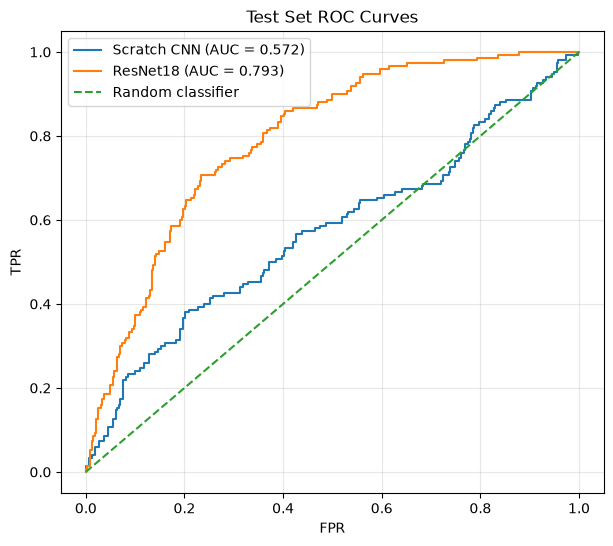

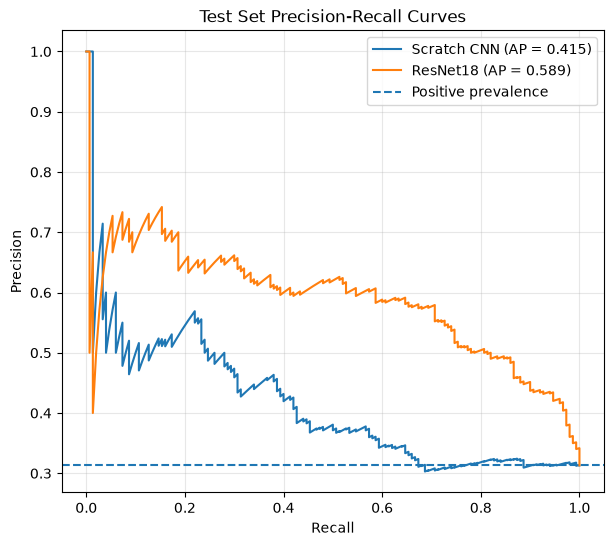

In [12]:
# Calculate curve values
scratch_fpr, scratch_tpr, _ = roc_curve(test_labels, scratch_test_probs)
resnet_fpr, resnet_tpr, _ = roc_curve(test_labels, resnet_test_probs)

scratch_precision, scratch_recall, _ = precision_recall_curve(test_labels, scratch_test_probs)
resnet_precision, resnet_recall, _ = precision_recall_curve(test_labels, resnet_test_probs)

# Plot ROC curves
plt.figure(figsize=(7, 6))
plt.plot(scratch_fpr, scratch_tpr, label=f"Scratch CNN (AUC = {scratch_test_metrics['ROC-AUC']:.3f})")
plt.plot(resnet_fpr, resnet_tpr, label=f"ResNet18 (AUC = {resnet_test_metrics['ROC-AUC']:.3f})")
plt.plot([0, 1], [0, 1], linestyle="--", label="Random classifier")
plt.xlabel("FPR")
plt.ylabel("TPR")
plt.title("Test Set ROC Curves")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

# Plot Precision-Recall curves
plt.figure(figsize=(7, 6))
plt.plot(scratch_recall, scratch_precision, label=f"Scratch CNN (AP = {scratch_test_metrics['Average Precision']:.3f})")
plt.plot(resnet_recall, resnet_precision, label=f"ResNet18 (AP = {resnet_test_metrics['Average Precision']:.3f})")
plt.axhline(y=test_labels.mean(), linestyle="--", label="Positive prevalence")
plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("Test Set Precision-Recall Curves")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

## 06. Comparing both models

#### Quantitative Performance

| Metric | Scratch CNN | ResNet18 |
| ------ | ----------- | -------- |
| Accuracy | 0.5532 | 0.7328 |
| Precision | 0.3644 | 0.5579 |
| Recall | 0.5733 | 0.7067 |
| F1-score | 0.4456 | 0.6235 |
| ROC-AUC | 0.5722 | 0.7927 |
| Average Precision | 0.4147 | 0.5895 |

ResNet18 outperformed the Scratch CNN across all 6 evaluation metrics, demonstrating substantially better classification performance on the held-out test set. This suggests that transfer learning with ImageNet-pretrained weights provided a considerable advantage over training a small CNN from random initialisation. 

#### Confusion Matrix Analysis

The improvement was also reflected in the confusion matrices. Compared with the scratch CNN, ResNet18 correctly identified 66 more negative images than scratch CNN (245 vs 179) and 20 more positive images (106 vs 86). It also produced 66 fewer false positives (84 vs 150) and 20 fewer false negatives (44 vs 64). 

This indicates a meaningful improvement in identifying both classes, rather than a performance gain achieved by favouring 1 class at the expense of the other. 

Yet, ResNet18 still failed to identify 44 of 150 Effusion-positive images, corresponding to a false-negative rate of 29.3% (recall of 70.7%). This is an important limitation in a medical imaging classification task, where missed positive findings may have significant clinical implications.

#### Interpretation

Although ResNet18 demonstrated better overall performance, neither model should be considered clinically reliable based on these results alone. The evaluation is based on a curated dataset with relatively small number of unique patients in the test set, and differences in class prevalence and AP/PA projection distribution should also be considered when interpreting generalisability.

The classification thresholds for both models were selected using validation data and applied unchanged to the held-out test set. 

## 07. Grad-CAM

Using ResNet18, the stronger-performing model, we will select a few existing representative test images, generate Grad-CAM heatmaps using ResNet18's final convolutional layer, overlay the heatmaps on the original images and examine whether the highlighted regions appear anatomically or radiographically meaningful. 

### 7.1 Select few representative test Effusion-positive images

In [13]:
# Identify TP and FN indices
tp_indices = np.where((test_labels == 1) & (resnet_test_preds == 1))[0]
fn_indices = np.where((test_labels == 1) & (resnet_test_preds == 0))[0]
print("TPs:", len(tp_indices))
print("FNs:", len(fn_indices))

TPs: 106
FNs: 44


In [14]:
# Inititalise
selected_indices = []
used_patient_ids = set()

# Select 2 TPs and 2 FNs from different patient IDs
for candidates in [tp_indices, fn_indices]:
    selected_count = 0
    for index in candidates:
        patient_id = int(test_dataset.df.iloc[index]["Patient ID"])
        if patient_id not in used_patient_ids:
            selected_indices.append(index)
            used_patient_ids.add(patient_id)
            selected_count += 1
        if selected_count == 2:
            break

# Display selected examples
for index in selected_indices:
    row = test_dataset.df.iloc[index]
    print(
        f"Index: {index} | "
        f"Image: {row['Image Index']} | "
        f"Patient ID: {row['Patient ID']} | "
        f"True label: {test_labels[index]} | "
        f"Predicted probability: {resnet_test_probs[index]:.4f} | "
        f"Predicted class: {resnet_test_preds[index]}")

Index: 5 | Image: 00000013_004.png | Patient ID: 13 | True label: 1 | Predicted probability: 0.7522 | Predicted class: 1
Index: 16 | Image: 00000032_001.png | Patient ID: 32 | True label: 1 | Predicted probability: 0.9978 | Predicted class: 1
Index: 45 | Image: 00000041_006.png | Patient ID: 41 | True label: 1 | Predicted probability: 0.0013 | Predicted class: 0
Index: 68 | Image: 00000116_028.png | Patient ID: 116 | True label: 1 | Predicted probability: 0.2751 | Predicted class: 0


### 7.2 GradCAM class

Grad-CAM uses gradients flowing back from output to estimate which spatial regions contributed positively to the model's Effusion prediction.

In [15]:
class GradCAM:
    def __init__(self, model, target_layer):
        self.model = model
        self.target_layer = target_layer
        self.activations = None
        self.gradients = None
        self.forward_hook = target_layer.register_forward_hook(self.save_activations)
        self.backward_hook = target_layer.register_full_backward_hook(self.save_gradients)
    def save_activations(self, module, input, output):
        self.activations = output.detach()
    def save_gradients(self, module, grad_input, grad_output):
        self.gradients = grad_output[0].detach()
    def generate(self, image):
        self.model.eval()
        self.model.zero_grad()
        logits = self.model(image)
        # Backpropagate from model's output logit
        logits.backward()
        # Average gradients across spatial dimensions
        weights = torch.mean(self.gradients, dim=(2, 3), keepdim=True)
        # Weighted combination of feature maps
        cam = (weights * self.activations).sum(dim=1)
        # Retain positive contributions
        cam = torch.relu(cam)
        # Normalise heatmap
        cam = cam - cam.min()
        cam = cam / (cam.max() + 1e-8)
        return cam.squeeze().cpu().numpy()
    def remove_hooks(self):
        self.forward_hook.remove()
        self.backward_hook.remove()               

### 7.3 Generate heatmaps

In [16]:
# Initialise Grad-CAM using final convolutional block of ResNet18 (layer4[-1])
grad_cam = GradCAM(
    model=resnet_model,
    target_layer=resnet_model.layer4[-1])

# Generate Grad-CAM heatmaps for 4 selected images using preprocessed tensors of test_dataset
gradcam_results = {}
for index in selected_indices:
    image, label, patient_id = test_dataset[index]
    image = image.unsqueeze(0).to(DEVICE)
    heatmap = grad_cam.generate(image)
    gradcam_results[index] = heatmap
    print(
        f"Index: {index} | "
        f"Heatmap shape: {heatmap.shape} | "
        f"Range: {heatmap.min():.4f} to {heatmap.max():.4f}")

Index: 5 | Heatmap shape: (7, 7) | Range: 0.0000 to 1.0000
Index: 16 | Heatmap shape: (7, 7) | Range: 0.0000 to 1.0000
Index: 45 | Heatmap shape: (7, 7) | Range: 0.0000 to 1.0000
Index: 68 | Heatmap shape: (7, 7) | Range: 0.0000 to 1.0000


### 7.4 Overlay Grad-CAM onto original CXR

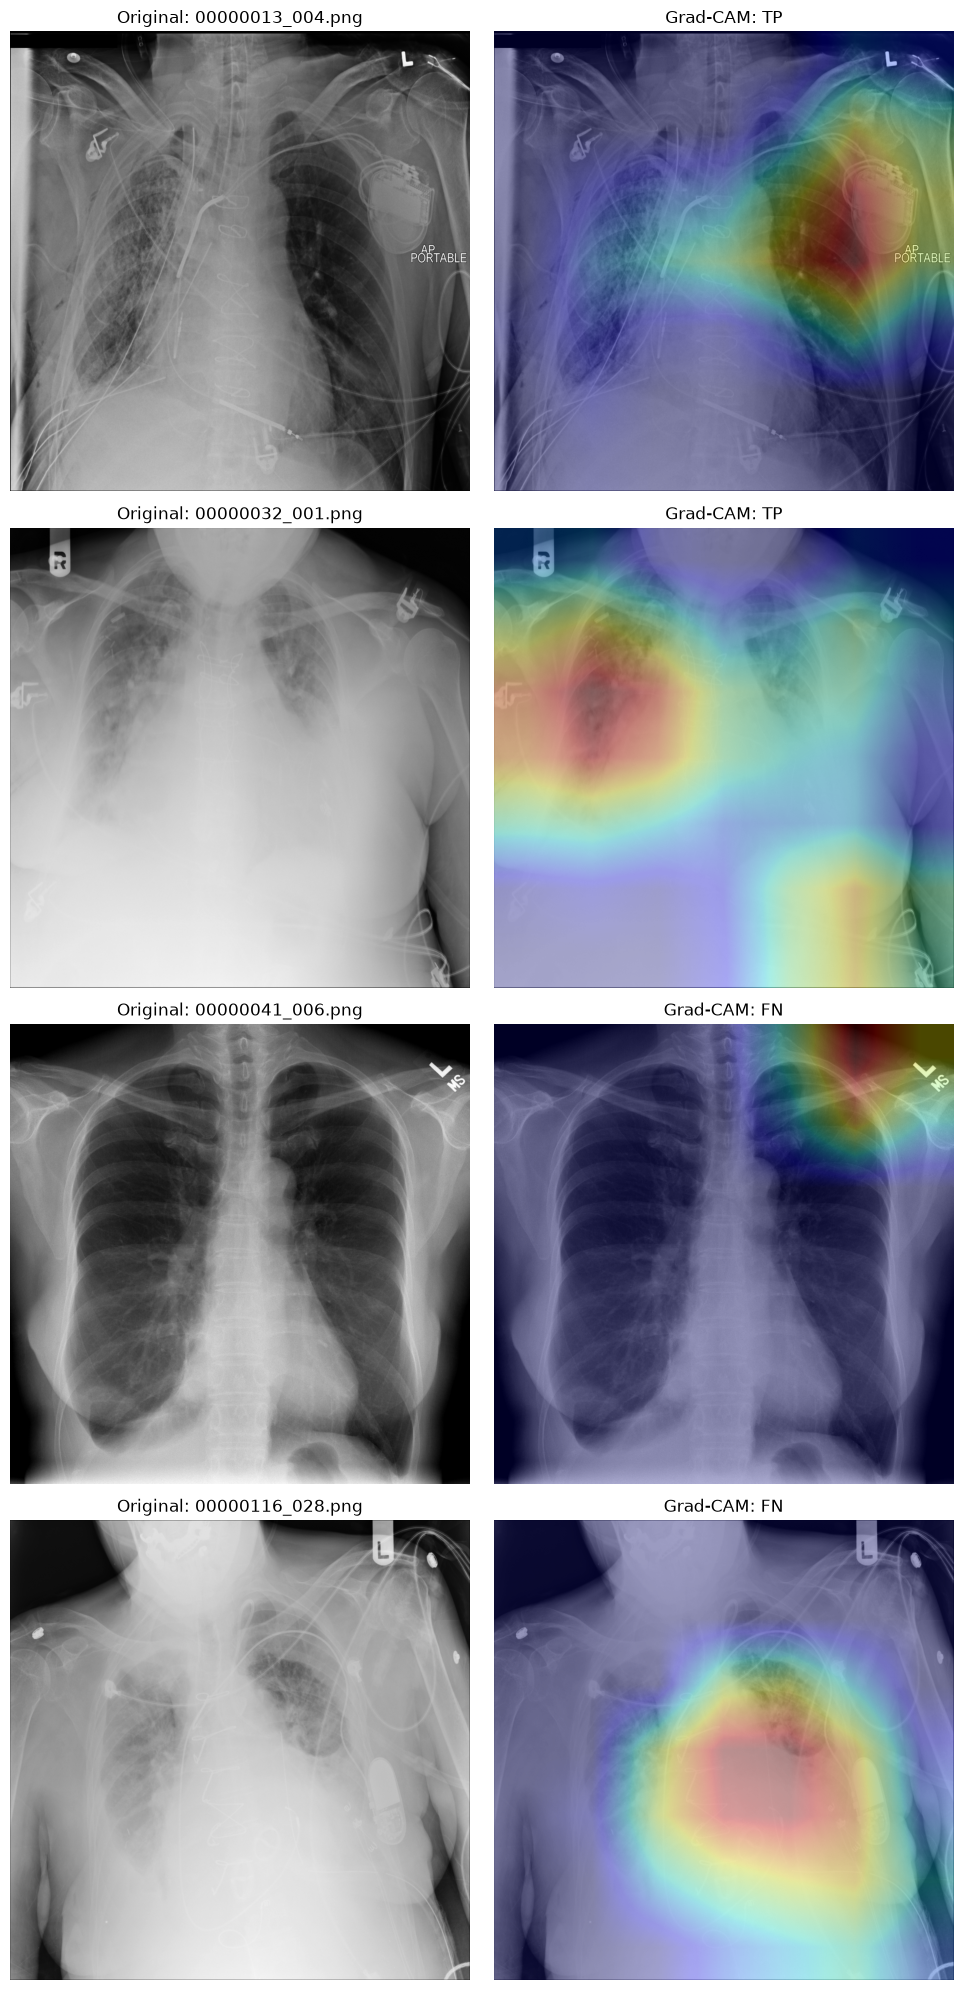

In [17]:
from PIL import Image
import torch.nn.functional as F

fig, axes = plt.subplots(4, 2, figsize=(10, 20))
for row, index in enumerate(selected_indices):
    image_name = test_dataset.df.iloc[index]["Image Index"]
    # Load original CXRs
    original_image = Image.open(IMAGE_DIR / image_name).convert("L")
    original_array = np.array(original_image)
    # Resize heatmap to original image dimensions
    heatmap_tensor = torch.tensor(gradcam_results[index]).unsqueeze(0).unsqueeze(0)
    resized_heatmap = F.interpolate(
        heatmap_tensor,
        size=original_array.shape,
        mode="bilinear",
        align_corners=False).squeeze().numpy()
    # Display original CXR
    axes[row, 0].imshow(original_array, cmap="gray")
    axes[row, 0].set_title(f"Original: {image_name}")
    # Display Grad-CAM overlay
    axes[row, 1].imshow(original_array, cmap="gray")
    axes[row, 1].imshow(resized_heatmap, cmap="jet", alpha=0.3, vmin=0, vmax=1)
    axes[row, 1].set_title(f"Grad-CAM: {'TP' if index in tp_indices else 'FN'}")
    for ax in axes[row]:
        ax.axis("off")
plt.tight_layout()
plt.show()        

### 7.5 Grad-CAM Visualisation and Interpretation

Grad-CAM was applied to 4 selected ResNet18 test predictions: 2 TPs and 2 FNs, which each example representing a different patient.

3 of 4 heatmaps highlighted regions within the thoracic cavity. Notably, 2 highlighted the lung bases, which is anatomically plausible given the typical lcoation of pleural effusions.

However, 2 observations raised concerns:
- 1 TP prediction focuses on a medical device rather than the surround lung anatomy, suggesting the possibility of reliance on incidental features.
- 1 FN prediction highlighted the shoulder region outside the thoracic cavity, indicating that the model may not consistently focus on clinically relevant anatomical structures.

There were no obvious differences in attention patterns between the TP and FN examples.

These observations suggest that ResNet18 may have learned some anatomically relevant features, but its predictions may also be influenced by incidental or less relevant image features. Grad-CAM provides an indication of model attention rather than definitive evidence of features driving its predictions. Further investifation using a larger and more representative sample would be necessary.

## 08. Evaluation and Comparison Summary

### Limitations

Several limitations should be considered when interpreting results:
- **Dataset composition**: The curated dataset contains 3241 images with only 52 unique patients represented in the held-out test set.
- **Distribution difference**: The test set has a higher Effusion prevalence and different AP/PA projection distribution compared with the training and validation sets.
- **Patient-level clustering**: Multiple images from the same patient are present within individual splits. Although there are no patient overlap between splits, predictions from images belonging to the same patient may not be statistically independent.
- **Classification scope**: The model distinguishes Effusion-positive images from images labelled No Finding. It does not identify or localise effusions, and the positive class may contain additional findings.
- **Model interpretability**: Grad-CAM provides coarse visual explanations rather than definitive evidence of features influencing predictions. Radiographic knowledge can help assess whether highlighted regions are anatomically plausible, but visual plausibility alone does not establish that the model has learned clinically meaningful features.
- **External validity**: Performance on this curated dataset does not establish generalisability to other institutions, patient populations or imaging systems.

### Conclusion

This project explored the application of CNNs to binary classification of pleural effusion in chest X-ray images, covering dataset curation, image preprocessing, CNN development, transfer learning, model evaluation, and interpretability.

ResNet18, using ImageNet-pretrained weights, outperformed the CNN trained from random initialisation across all 5 test evaluation metrics, achieving a ROC-AUC of 0.7927 and an F1-score of 0.6235, demonstrating the benefit of transfer learning for the selected classification task.

My background in diagnostic radiography provided a valuable foundation throughout this project. Familiarity with chest radiographic anatomy, AP/PA projections, image characteristics and radiographic findings helped me understand the data beyond its numerical representation. 

The visualisation findings highlighted an important distinction between classification performance and clinically meaningful interpretation. While some predictions focused on anatomically plausible regions, other appeared to rely on less relevant features. Recognising these limitations required more than technical evaluation alone; it also required an understanding of the underlying radiographic images.

Overall, this project demonstrated how my existing radiography knowledge can complement technical skills in machine learning. It reinforced my interest in medical imaging AI, particularly in bridging clinical understanding with computational methods to develop and evaluate AI applications in healthcare.

Although further validation using larger and more representative datasets would be necessary before any clinical application, this project represents an initial step towards integrating my clinical background with AI and medical imaging research. 